# Data Prep/Setup

## Imports

In [41]:
# Import standard data prep and eda libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd



## Data Sources

### Hatcheries

In [42]:

# # Import from arcgis 
# url = ("https://services9.arcgis.com/6EuFgO4fLTqfNOhu/arcgis/rest/services/"
#        "PA_Hatcheries/FeatureServer/0/query?where=1%3D1&outFields=*&f=geojson")

# hatch = gpd.read_file(url)
# print("First few rows of the hatcheries data:")
# print(hatch.head())
# # Download local copy of hatcheries data
# hatch.to_file("../data/raw/pa_hatcheries.gpkg", driver="GPKG")

# url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
# states = gpd.read_file(url)

# pa = states[states["STUSPS"] == "PA"]

# pa.to_file("../data/raw/pa_boundary.gpkg", driver="GPKG")

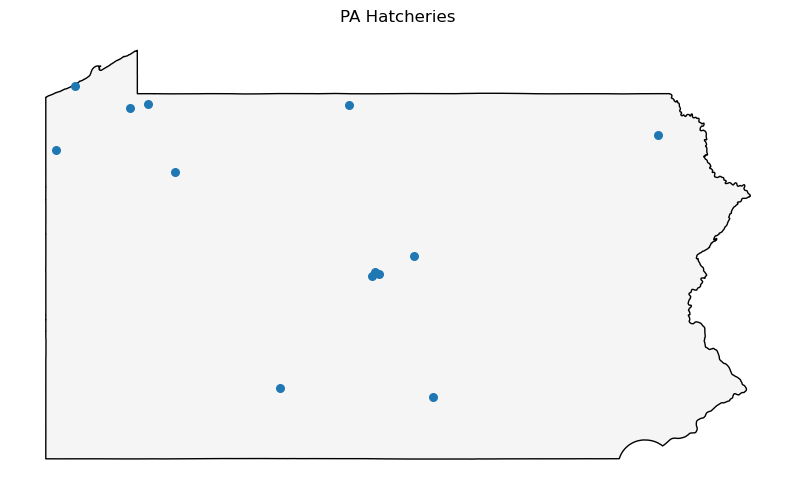

In [43]:

# 1. Load both layers
pa = gpd.read_file("../data/raw/pa_boundary.gpkg")
hatch = gpd.read_file("../data/raw/pa_hatcheries.gpkg")

# 2. Match the CRS (always before overlaying)
hatch = hatch.to_crs(pa.crs)

# 3. Plot
fig, ax = plt.subplots(figsize=(10, 6))
#Basemap
pa.plot(ax=ax, color="whitesmoke", edgecolor="black")
#Hatcheries
hatch.plot(ax=ax, color="tab:blue", markersize=30)

ax.set_title("PA Hatcheries")
ax.set_axis_off()



In [44]:
# Review hatcheries data

hatch.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   REGION      13 non-null     object  
 1   ID          13 non-null     int32   
 2   COUNTY      13 non-null     object  
 3   FULL_NAME   13 non-null     object  
 4   NAME        13 non-null     object  
 5   VISITOR_CE  13 non-null     object  
 6   TROUT       13 non-null     object  
 7   WARM_COOL   13 non-null     object  
 8   STEEL_SALM  13 non-null     object  
 9   Link        13 non-null     object  
 10  Long_       13 non-null     float64 
 11  Lat         13 non-null     float64 
 12  County_Lin  13 non-null     object  
 13  geometry    13 non-null     geometry
dtypes: float64(2), geometry(1), int32(1), object(10)
memory usage: 1.5+ KB


In [45]:
# What does the data look like
print("First few rows of the hatcheries data:")
hatch.head()


First few rows of the hatcheries data:


,REGION,ID,COUNTY,FULL_NAME,NAME,VISITOR_CE,TROUT,WARM_COOL,STEEL_SALM,Link,Long_,Lat,County_Lin,geometry
0,Southcentral,11,Bedford,Reynoldsdale State Fish Hatchery,Reynoldsdale,y,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-78.58000,40.15750,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-78.58 40.15751)
1,Northcentral,8,Centre,Benner Spring State Fish Hatchery,Benner Spring,,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.81694,40.85762,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.81694 40.85763)
2,Northcentral,9,Centre,Bellefonte State Fish Hatchery,Bellefonte,y,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.79402,40.88273,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.79402 40.88274)
3,Northcentral,7,Centre,Pleasant Gap State Fish Hatchery,Pleasant Gap,,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.75750,40.86878,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.7575 40.86879)
4,Northcentral,10,Clinton,Tylersville State Fish Hatchery,Tylersville,,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.47062,40.98244,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.47062 40.98245)


In [46]:
# Website shows 12 hatcheries with data. How many do we have in our dataset?
print("Number of hatcheries in the dataset:", hatch.shape[0])

# Print out the full list of names to compare to website
print("Names of hatcheries in the dataset:")
print(hatch["FULL_NAME"])

Number of hatcheries in the dataset: 13
Names of hatcheries in the dataset:
0       Reynoldsdale State Fish Hatchery
1      Benner Spring State Fish Hatchery
2         Bellefonte State Fish Hatchery
3       Pleasant Gap State Fish Hatchery
4        Tylersville State Fish Hatchery
5          Huntsdale State Fish Hatchery
6     Pleasant Mount State Fish Hatchery
7             Oswayo State Fish Hatchery
8           Fairview State Fish Hatchery
9              Corry State Fish Hatchery
10        Union City State Fish Hatchery
11        Linesville State Fish Hatchery
12          Tionesta State Fish Hatchery
Name: FULL_NAME, dtype: object


In [47]:
# Does the Trout column y/n explain the one extra? Perhaps a non-trout hatchery?

print("Values in the Trout column:")
non_trout = hatch[hatch["TROUT"] != "y"]
non_trout

Values in the Trout column:


,REGION,ID,COUNTY,FULL_NAME,NAME,VISITOR_CE,TROUT,WARM_COOL,STEEL_SALM,Link,Long_,Lat,County_Lin,geometry
8,Northwest,1,Erie,Fairview State Fish Hatchery,Fairview,,,,y,http://fishandboat.com/Fish/Stocking/StateFish...,-80.27630,42.04262,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-80.2763 42.04263)
10,Northwest,3,Erie,Union City State Fish Hatchery,Union City,,,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-79.81782,41.90750,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-79.81782 41.90751)
12,Northwest,13,Forest,Tionesta State Fish Hatchery,Tionesta,y,,y,y,http://fishandboat.com/Fish/Stocking/StateFish...,-79.44988,41.50756,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-79.44988 41.50757)


*Tionesta* and *Fairview* do not have any production/yield data on the website and has a null for Trout - https://www.pa.gov/agencies/fishandboat/about-us/agency-overview/bureaus/state-fish-hatcheries/tionesta-state-fish-hatchery
https://www.pa.gov/agencies/fishandboat/about-us/agency-overview/bureaus/state-fish-hatcheries/fairview-state-fish-hatchery

Think Union City is just a mussel hatchery. https://www.pa.gov/agencies/fishandboat/about-us/agency-overview/bureaus/field-operations/fisheries-management/union-city-aquatic-conservation-center

Looks like we just need the 10 y Trouts for our project. Side note: interesting scenario where we imagine the three non-trout hatcheries are converted over and see how that changes our run.


In [48]:
# drop the non-trout hatchery from the dataset
hatch_trout = hatch[hatch["TROUT"] == "y"]

hatch_trout.shape

(10, 14)

In [49]:
# Review hatcheries that are MORE than just trout hatcheries

mixed_hatcheries =  hatch_trout[(hatch_trout["WARM_COOL"] == "y") | (hatch_trout["STEEL_SALM"] == "y")]
mixed_hatcheries

,REGION,ID,COUNTY,FULL_NAME,NAME,VISITOR_CE,TROUT,WARM_COOL,STEEL_SALM,Link,Long_,Lat,County_Lin,geometry
1,Northcentral,8,Centre,Benner Spring State Fish Hatchery,Benner Spring,,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.81694,40.85762,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.81694 40.85763)
5,Southcentral,12,Cumberland,Huntsdale State Fish Hatchery,Huntsdale,y,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.30833,40.10306,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.30833 40.10307)
6,Northeast,6,Wayne,Pleasant Mount State Fish Hatchery,Pleasant Mount,y,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-75.44806,41.73972,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-75.44806 41.73973)
11,Northwest,2,Crawford,Linesville State Fish Hatchery,Linesville,y,y,y,y,http://fishandboat.com/Fish/Stocking/StateFish...,-80.42748,41.64583,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-80.42748 41.64584)


## Which have specific trout data?

Benner Spring have production specific to trout

Huntsdale have production specific to trout

Pleasant Mount State is multiple fish in the number

Linesville State fish Hatcherty has no data




c:\Users\loydg\anaconda3\Lib\site-packages\geopandas\geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


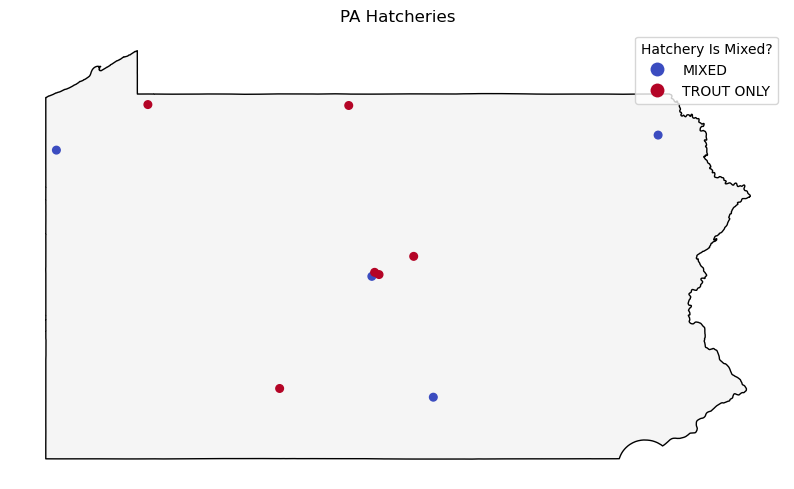

In [50]:
# Show trout only hatcheries versus mixed hatchers on the map (color distinguish)

# Create binary for trout only versus mixed hatcheries
# TRUE = mixed
hatch_trout["MIXED"] = (hatch_trout["WARM_COOL"] == "y") | (hatch_trout["STEEL_SALM"] == "y")

# Make MIXED = true be MIXED
hatch_trout["MIXED"] = hatch_trout["MIXED"].replace({True: "MIXED", False: "TROUT ONLY"})
fig, ax = plt.subplots(figsize=(10, 6))
#Basemap
pa.plot(ax=ax, color="whitesmoke", edgecolor="black")

# plot hatch_trout with color distinction for mixed vs trout only
hatch_trout.plot(ax=ax, column="MIXED", cmap="coolwarm", markersize=30, legend=True)

ax.set_title("PA Hatcheries")
ax.set_axis_off()
#add legend title
ax.get_legend().set_title("Hatchery Is Mixed?")

### Export hatch_trout to data/processed

In [57]:
# export hatch_trout to data/processed as gpkg
hatch_trout.to_file("../data/processed/trout_hatcheries.gpkg", driver="GPKG")

## Review production per hatchery

In [52]:
# Import in pa_hatchery_production.csv
hatchery_production = pd.read_csv("../data/raw/pa_hatchery_production.csv")

# review
print(hatchery_production)
print(hatchery_production.shape)

         hatchery  production_value                 production_units  \
0      Bellefonte          338918.0                              lbs   
1   Benner Spring          336366.0                              lbs   
2       Huntsdale          461280.0                              lbs   
3    Reynoldsdale          161932.0                              lbs   
4     Tylersville          372782.0                              lbs   
5           Corry          145851.0                              lbs   
6          Oswayo          181261.0                              lbs   
7    Pleasant Gap          256164.0                              lbs   
8  Pleasant Mount        25963170.0  count (fry/fingerling/yearling)   
9      Linesville               NaN                              NaN   

                                       label_on_page  \
0                           Average Trout Production   
1                           Average Trout Production   
2                           Average Tro

In [53]:
# Sum total of production after filtering out NAs and "PLeasant Mount" 
total_production = hatchery_production[
    (hatchery_production["production_value"].notnull()) &
    (hatchery_production["hatchery"] != "Pleasant Mount")
]["production_value"].sum()

# Print formatted with commas
total_production_formatted = "{:,.0f}".format(total_production)
print(f"Total production: {total_production_formatted}")

Total production: 2,254,554


## Overlay Streams

In [54]:
# Import streams for maps

class_a = gpd.read_file("../data/raw/pa_class_a_trout_streams.gpkg")

pa_stocked = gpd.read_file("../data/raw/pa_stocked_trout_streams.gpkg")



In [59]:
class_a.sample(20)

,WtrLatDD,WtrLonDD,SecNum,SecSubbasi,SecCnt1Per,SecCnt2Per,SecUpperLi,SecLowerLi,Length_ft,Length_MI_GIS,...,GIS_Key,COUNTY_NAM,Region,MapID,GlobalID,Fishery,Region_2,MapID_2,RFP_WaterID,geometry
370,40.907500,-76.510833,5,5,50.0,50.0,6.250,3.11,16523.819430,3.129511,...,161-5,Northumberland,Northcentral,113.0,{3D1F3FC6-09AC-4394-919A-24DD2EEE724A},Brown,None,NaN,161,"MULTILINESTRING ((-76.50296 40.83245, -76.5029..."
408,41.326944,-76.461944,1,5,100.0,0.0,1.930,0.00,10925.748483,2.069271,...,3247-1,Sullivan,Northeast,87.0,{DEAAC1E4-B3C6-42F3-9E8B-203F76034805},Brook,None,NaN,3247,"MULTILINESTRING ((-76.47048 41.35269, -76.4702..."
1171,40.976944,-76.978889,2,6,NaN,NaN,11.590,5.09,35045.755164,6.637454,...,3217-2,Union,Northcentral,NaN,{BD29ED67-6066-4B58-8964-2E9250111A96},None,None,NaN,3217,"MULTILINESTRING ((-77.11657 41.0119, -77.11653..."
605,40.272500,-78.978611,1,18,NaN,NaN,11.000,9.96,6748.188845,1.278066,...,2179-1,Somerset,Southwest,50.0,{7556D591-3832-4512-9A15-BE5881ADF975},Brook Trout Fishery,None,NaN,2179,"MULTILINESTRING ((-79.09168 40.23427, -79.0916..."
442,41.089167,-75.850000,2,5,100.0,0.0,3.480,0.00,18238.908018,3.454339,...,2308-2,Luzerne,Northeast,40.0,{017DBAE5-356D-49FF-8652-0D2236608CC2},Brook,None,NaN,2308,"MULTILINESTRING ((-75.8162 41.12187, -75.81658..."
866,41.737221,-78.242500,1,16,NaN,NaN,1.510,0.00,7956.549195,1.506922,...,5602-1,Mckean,Northcentral,410.0,{ABB9645F-D20D-48A9-AB25-5485388AEFD4},Mixed Brook/Brown Trout Fishery,None,NaN,5602,"MULTILINESTRING ((-78.26824 41.73131, -78.2678..."
855,41.545834,-75.216942,1,1,NaN,NaN,4.550,1.91,13404.983321,2.538823,...,668-1,Wayne,Northeast,277.0,{9EC19C36-FB86-4C32-AB97-BAA702AC9CCD},Wild Brook Trout Fishery,None,NaN,668,"MULTILINESTRING ((-75.18143 41.59307, -75.1814..."
300,40.618611,-75.202778,2,2,0.0,0.0,0.960,0.00,5095.657072,0.965087,...,3202-2,Northampton,Southeast,34.0,{C6473AB2-8B4C-4A5A-92E0-52FD11DB373E},Brown,None,NaN,3202,"MULTILINESTRING ((-75.21783 40.61694, -75.2177..."
946,41.842868,-78.693378,1,16,NaN,NaN,2.680,0.00,14174.284613,2.684524,...,10728-1,McKean,Northcentral,469.0,{F8013395-7569-43D5-ADA2-6F37BB51B872},Wild Brown Trout Fishery,None,NaN,10728,"MULTILINESTRING ((-78.68517 41.81318, -78.6854..."
1034,41.593889,-78.057778,4,8,NaN,NaN,2.900,0.00,16190.069565,3.066301,...,3546-4,Potter,Northcentral,NaN,{AF966BCB-5389-40E6-81B9-C083E9B670AA},Wild Brown Trout Fishery,None,NaN,3546,"MULTILINESTRING ((-78.09146 41.62671, -78.0914..."


In [62]:
class_a.shape[0]

1361

In [60]:
pa_stocked.sample(20)

,GNIS_ID,Length_MI_,Mid_Lat,Mid_Long,OBJECTID,GNIS_Name,County,Year_Round,Early_Open,Region,...,Limits,EarlyOpen_Desc,WtrLatLon,UniqueID,RFP_WaterID,GIS_Key,Reg_Name,Reg_Link,GlobalID,geometry
997,1169789.0,5.789086,40.415330,-78.457050,1015,Blair Gap Run,Blair,N,None,Southcentral,...,Outflow of lower Blair Gap Muleshoe Reservoir ...,None,402600782502,481.0,3211,3211-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{3384B974-0644-48CB-9846-9A3ED1DB3717},"MULTILINESTRING ((-78.50302 40.42858, -78.503 ..."
885,1198971.0,2.146873,41.347855,-77.913420,903,Kettle Creek,Clinton,N,None,Northcentral,...,ALVIN R. BUSH DAM down to OWL HOLLOW,None,411802775020,187.0,3351,3351-11,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{C7C9A93A-C2A3-4788-BDDC-A97993882F8A},"MULTILINESTRING ((-77.92282 41.35795, -77.9234..."
405,1168401.0,7.894973,40.484930,-76.880440,414,Armstrong Creek,Dauphin,N,None,Southcentral,...,RUTTER RD (SR4001) down to RT 225 (SR0225),None,402855765605,510.0,2979,2979-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{B0DF7E99-152C-40C1-892F-515B66ABE12F},"MULTILINESTRING ((-76.8491 40.50899, -76.84952..."
669,1175656.0,2.253445,39.796230,-79.246150,682,Glade Run,Somerset,N,None,Southwest,...,HIGH POINT LK down to MOUTH,None,394833791459,625.0,3738,3738-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{7C35625F-CD20-433A-B3CD-688A72301875},"MULTILINESTRING ((-79.23714 39.78305, -79.2371..."
920,1190911.0,1.615823,41.574420,-75.267049,938,West Branch Lackawaxen River,Wayne,N,None,Northeast,...,OUTLET SEALYVILLE DM down to CONF. W LACKAWAXEN R,None,413439751515,332.0,2280,2280-7,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{C8D36F09-8197-4BCB-B1EA-BCDF9C3E0018},"MULTILINESTRING ((-75.28026 41.57657, -75.2800..."
931,592371.0,3.984656,39.908208,-77.482985,949,Conococheague Creek,Franklin,N,None,Southcentral,...,FORMER DAM AT BIRCH RUN RESERVOIR down to BLAC...,None,394317774725,316.0,1819,1819-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{30D7F945-4428-4120-9E60-EE25CA53427B},"MULTILINESTRING ((-77.45374 39.91859, -77.4538..."
837,1193629.0,5.795118,41.299030,-76.459700,853,West Branch Fishing Creek,Sullivan,N,None,Northeast,...,CONFL HEMLOCK RN down to SULLIVAN COLUMBIA CO ...,None,411633762223,354.0,6227,6227-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{09CD4CB1-307E-4020-B904-C43C394B7A0B},"MULTILINESTRING ((-76.50657 41.31796, -76.5064..."
715,1192843.0,1.420309,40.330632,-79.814478,729,Long Run,Allegheny,N,None,Southwest,...,CONFL WITH JACKS RUN down to UPPER BNDRY VERSA...,None,401933795033,405.0,2073,2073-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{797A4059-BF07-4CD1-8493-8D6790FB23C8},"MULTILINESTRING ((-79.80719 40.33731, -79.8072..."
614,1199339.0,2.619895,41.484490,-78.652910,627,Powers Run,Elk,N,None,Northcentral,...,2ND TRIB UPST SR 0255 BRIDGE down to MOUTH,None,412845784024,150.0,2921,2921-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{482CED53-3EF0-4B7D-8996-AC9A3FEA9621},"MULTILINESTRING ((-78.63176 41.49016, -78.6318..."
91,1198127.0,3.483736,39.876670,-80.479409,92,South Fork Dunkard Fork,Greene,N,None,Southwest,...,SR3016 AT SMITH BRIDGE down to MOUTH,None,395333802841,448.0,3751,3751-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{04BB643C-B9F3-427E-8141-6B59EEA243F4},"MULTILINESTRING ((-80.47443 39.86044, -80.4744..."


In [61]:
pa_stocked.shape[0]

1064

In [65]:
pa_stocked['GNIS_Name'].value_counts()

GNIS_Name
Pine Creek         21
Kettle Creek       12
Fishing Creek      10
Buffalo Creek       8
Oil Creek           7
                   ..
Enlow Fork          1
Carbaugh Run        1
Bell Run            1
Pennypack Creek     1
Peters Creek        1
Name: count, Length: 611, dtype: int64

### Nurseries

In [ ]:
# import from raw data the coop_nurseries
coop_nurseries = gpd.read_file("../data/raw/Coop_nurseries.geojson")

coop_nurseries.sample(20)



,LAT,LONG_,GlobalID,OBJECTID_1,NURSERY_NA,SPONSOR_NA,COUNTY,REGION,OPEN_DATE,ID,geometry
149,41.56,-78.94,{ED680BE2-E8C4-4A20-AF23-F7EF06486B6B},2132,Pigs Ear,Hi-La Sportsmen Assoc. ...,Elk,NORTHCENTRAL,1952,70,POINT (-78.93618 41.56363)
98,41.06,-75.05,{A29C432D-BBC3-4F7C-BFCB-539AD0A19259},2081,Resica Falls,Resica Falls Trout Club BSA ...,Monroe,NORTHEAST,1987,137,POINT (-75.05441 41.06416)
157,40.92,-79.08,{F5B7B8C6-DB87-487C-B8D6-016682356D90},2140,Kunselman,Perry Township Sportsmen (Jefferson) ...,Jefferson,NORTHCENTRAL,1987,128,POINT (-79.07985 40.92436)
134,40.61,-78.37,{DC57E95E-4A92-4902-8F06-9ABDC1B3D26B},2117,Bell's Gap Run,Bellwood Sportsmen Assoc. ...,Blair,SOUTHCENTRAL,1985,19,POINT (-78.36801 40.61464)
88,40.91,-79.46,{97DD811D-AC95-4C12-8544-BF48075305B1},2071,Pine Creek Spts.,Pine Creek Sportsmen Club ...,Armstrong,SOUTHWEST,1977,129,POINT (-79.45916 40.91253)
9,40.34,-78.76,{09E572A0-6B49-40A9-82CD-B130DCA8190B},1992,Wilmore Trout Nursery,Wilmore Sportsmen's Association ...,Cambria,SOUTHWEST,1983,59,POINT (-78.76148 40.34376)
28,39.98,-79.58,{2A5A6F44-EE24-4F59-BA77-2F44635EBF91},2011,South Connellsville,South Connellsville Rod & Gun Club ...,Fayette,SOUTHWEST,1988,153,POINT (-79.58499 39.98292)
57,40.86,-77.28,{5FCD0A67-6776-43E8-85FB-2341A11D639C},2040,Union Co. Spts.,Union County Sportsmen Club ...,Union,NORTHCENTRAL,2004,168,POINT (-77.28485 40.86155)
7,42.03,-80.30,{09A54765-3E3F-4F36-9BAA-57965683FB04},1990,Ro-Ze,3 C.U. Trout Assoc. ...,Erie,NORTHWEST,1966,7,POINT (-80.30216 42.03025)
92,40.31,-78.12,{9B4CA9DE-FE58-420A-9A70-01330F317B64},2075,Youth Forestry Camp #3,Youth Forestry Camp #3 ...,Huntingdon,SOUTHCENTRAL,2001,180,POINT (-78.12057 40.31199)


In [ ]:
coop_nurseries.